# Stock-and-flow model with custom equations

This notebook shows how to write a quantitative stock-and-flow model in SIP, with every
relationship given by a custom equation, the way applied system dynamics models are written.
The model, [`StockFlow.xlsx`](StockFlow.xlsx), is synthetic and in normalised units: a national
training programme turns **trainees** into **certified installers**, who **retrofit homes**;
retrofitted homes make the trade visible and attract new trainees. It has 11 variables and
runs in seconds. If you are new to SIP, start with the [Minimal tutorial](Minimal.ipynb).

| Feature | In this model |
|---|---|
| Stocks that integrate their net flow | `Homes retrofitted` = `Homes retrofitted per year` |
| A transfer between two stocks with one named parameter | `- #completion_rate * Trainees` leaves `Trainees`, `#completion_rate * Trainees` enters `Certified installers (FTE)` |
| Parameter ranges in a `Parameters` sheet | `#completion_rate`, `#enrol_rate`, `#attrition_rate`, ... |
| A local parameter | `#1` in `Enrolment`, range `[0, parameter_value_aux]` |
| A policy that ramps in with time `t` | `National programme (phase-in)` = `np.clip((t - 2) / 3, 0, 1)` |
| Names with spaces and punctuation, one inside another | `Certified installers (FTE)`; `Homes retrofitted` and `Homes retrofitted per year` |
| Balancing and reinforcing feedback loops | attrition and market saturation; retrofits → awareness → enrolment |
| Levers and a variable of interest | three constants with `Tags` = 1; `Homes retrofitted` (`VOI`) |

In [1]:
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.max_colwidth", None)
book = pd.read_excel("StockFlow.xlsx", sheet_name=None)   # every sheet of the workbook
for sheet in ("Elements", "Connections", "Parameters"):
    print(sheet)
    display(book[sheet].fillna(""))

Elements


,Label,Type,Tags,Description,Equation
0,Trainees,stock,0,,Enrolment - #completion_rate * Trainees
1,Certified installers (FTE),stock,0,,#completion_rate * Trainees - Attrition
2,Homes retrofitted,stock,0,VOI,Homes retrofitted per year
3,Public awareness,stock,0,,#word_of_mouth * Homes retrofitted per year + 0.2 * Awareness campaign - #forgetting * Public awareness
4,Enrolment,auxiliary,0,,#enrol_rate * National programme (phase-in) * (1 + Training subsidy) + #1 * Public awareness
5,Attrition,auxiliary,0,,#attrition_rate * Certified installers (FTE) / (1 + Retention bonus)
6,Homes retrofitted per year,auxiliary,0,,#productivity * Certified installers (FTE) * (1 - Homes retrofitted)
7,National programme (phase-in),auxiliary,0,,"np.clip((t - 2) / 3, 0, 1)"
8,Training subsidy,constant,1,,
9,Awareness campaign,constant,1,,


Connections


,From,Type,To
0,Training subsidy,+,Enrolment
1,National programme (phase-in),+,Enrolment
2,Public awareness,+,Enrolment
3,Enrolment,+,Trainees
4,Trainees,+,Certified installers (FTE)
5,Certified installers (FTE),+,Attrition
6,Retention bonus,-,Attrition
7,Attrition,-,Certified installers (FTE)
8,Certified installers (FTE),+,Homes retrofitted per year
9,Homes retrofitted,-,Homes retrofitted per year


Parameters


,Name,Low,High
0,completion_rate,0.40,0.80
1,enrol_rate,0.10,0.30
2,attrition_rate,0.05,0.15
3,productivity,0.02,0.08
4,word_of_mouth,0.50,1.50
5,forgetting,0.25,0.50


## The workbook

**Elements.** Each stock's `Equation` is its rate of change, written as its net flow. A stock
without an equation would instead add up its incoming links with sampled, uncertain
coefficients: the right default for a qualitative causal loop diagram, not for a known
stock-and-flow structure. An auxiliary's equation gives its value: here the three flows and
the policy `National programme (phase-in)`, which depends on time alone and so needs no
incoming link. The levers are constants, zero unless an intervention sets them; their nonzero
`Tags` mark them as interventions. `VOI` in `Description` marks the outcome.

**Connections.** Every variable an equation uses is also drawn as a link with its polarity.
SIP warns when equation and diagram disagree, and the links define the feedback loops. A stock
that refers to its own level (`Trainees` in the equation of `Trainees`) needs no self-link.

**Parameters.** `#completion_rate` occurs in two equations but is one parameter: in every
parameter draw, what leaves `Trainees` enters `Certified installers (FTE)`. Its range, and the
ranges of the other named parameters, come from this sheet (`Low = High` would fix a value).
The local parameter `#1` is not listed: numbered parameters belong to their own equation and
range over `[0, parameter_value_aux]`.

In [2]:
from sip_systemsinsightpipeline import Extract, SDM

s = Extract("StockFlow.xlsx").extract_settings()
s.seed = 12345
s.N = 100                       # parameter draws
s.t_end = 20                    # years
s.time_unit = "years"
s.parameter_value_aux = 0.2     # range [0, 0.2] of the local parameter #1
s.parameter_value_stocks = 0.2  # not used: every stock has an equation
sdm = SDM(s)
voi = s.variable_of_interest[0]

Variable of interest: Homes retrofitted
with 3 intervention variables

3 feedback loops of maximum length 5
All loops have at least one stock
Custom equation for 'Trainees': Enrolment - #completion_rate * Trainees
  Variables used: {'Enrolment', 'Trainees'}
  Parameters (#): 0
  Named parameters: #completion_rate
  Intervention ($): No - intervention will be added to result

Custom equation for 'Certified installers (FTE)': #completion_rate * Trainees - Attrition
  Variables used: {'Attrition', 'Trainees'}
  Parameters (#): 0
  Named parameters: #completion_rate
  Intervention ($): No - intervention will be added to result

Custom equation for 'Homes retrofitted': Homes retrofitted per year
  Variables used: {'Homes retrofitted per year'}
  Parameters (#): 0
  Intervention ($): No - intervention will be added to result

Custom equation for 'Public awareness': #word_of_mouth * Homes retrofitted per year + 0.2 * Awareness campaign - #forgetting * Public awareness
  Variables used: {'Awar

SIP checked every equation against the model's variable names and the diagram, and found the
shared parameter: one draw of the model's parameters holds the same `#completion_rate` in both
equations, and `Enrolment` has its own `#1`.

In [3]:
params = sdm.sample_model_parameters()
for var in ["Trainees", "Certified installers (FTE)", "Enrolment"]:
    eq_params = params[var][f"__eq_params_{var}__"]
    print(f"{var:28s}", {name: round(float(value), 3) for name, value in eq_params.items()})

Trainees                     {'#completion_rate': 0.663}
Certified installers (FTE)   {'#completion_rate': 0.663}
Enrolment                    {'#1': 0.021, '#enrol_rate': 0.262}


## Baseline and interventions

All stocks start at zero, and nothing happens until the national programme starts at `t = 2`.
From then on enrolment, installers and retrofits grow **even without any intervention**. For
every parameter draw, `run_simulations` therefore simulates a no-intervention *baseline* as
well as one run per lever, and `get_intervention_effects` reports each lever's effect as the
difference between the two at the final time.

Running Simulations: 100%|██████████| 100/100 [00:03<00:00, 26.75it/s]


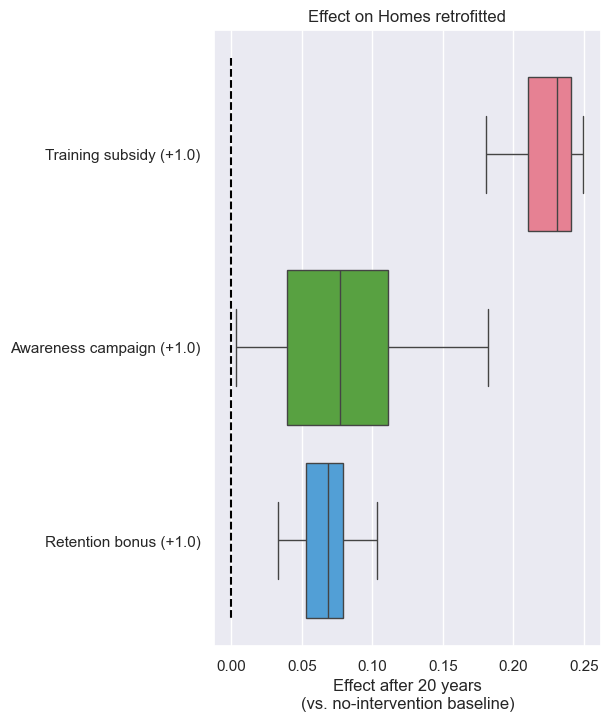

In [4]:
from sip_systemsinsightpipeline.plots import plot_simulated_intervention_ranking, plot_trajectories

sdm.t_eval = np.linspace(0, s.t_end, 81)   # record 81 time points for trajectory plots
df_sol_per_sample, param_samples = sdm.run_simulations()
effects = sdm.get_intervention_effects()
fig = plot_simulated_intervention_ranking(s, effects[voi], voi,
                                          xlabel="Effect after 20 years\n(vs. no-intervention baseline)")

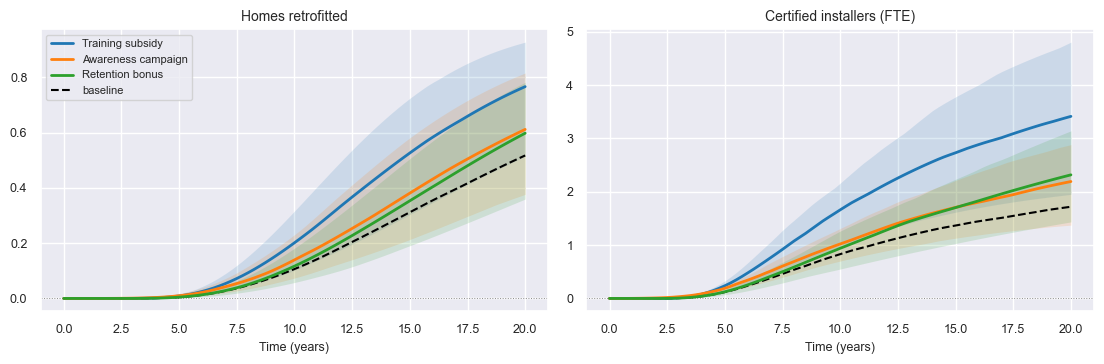

In [5]:
shown = [voi, "Certified installers (FTE)"]
fig = plot_trajectories(sdm, variables=shown, interventions="all")
for ax, var in zip(fig.axes, shown):            # add the no-intervention baseline (median)
    baseline = np.array([run[var].to_numpy() for run in sdm.df_sol_baseline_per_sample])
    ax.plot(sdm.t_eval, np.median(baseline, axis=0), color="black", ls="--", lw=1.5, label="baseline")
fig.axes[0].legend(fontsize=8);

In [6]:
raw = sdm.get_intervention_effects(relative_to=None)[voi]     # final values, nothing subtracted
baseline_final = [run[voi].iloc[-1] for run in sdm.df_sol_baseline_per_sample]
print(f"baseline: median final value {np.median(baseline_final):.3f}")
pd.DataFrame({"median final value": {k: np.median(v) for k, v in raw.items()},
              "median effect (vs baseline)": {k: np.median(v) for k, v in effects[voi].items()}}).round(3)

baseline: median final value 0.517


,median final value,median effect (vs baseline)
Training subsidy,0.766,0.231
Awareness campaign,0.611,0.077
Retention bonus,0.598,0.069


Without any intervention about half of the homes (median 0.52) are retrofitted after 20 years,
thanks to the programme. The raw final values (left column) would credit that to every lever;
the effects (right column) are what each lever adds. The training subsidy, which doubles
programme enrolment, adds the most, and most reliably. The awareness campaign works only
through `#1 * Public awareness` in `Enrolment`, and `#1` is uncertain over `[0, 0.2]`: hence its
wide spread. The retention bonus halves attrition.

## Which feedback loops drive the behaviour? (Loops That Matter)

Loops That Matter scores how much each feedback loop contributes to the change of the model's
variables over time. It evaluates the stocks' custom equations, including time `t`, exactly as
the simulation does. In the [Insulation tutorial](Insulation.ipynb) the baseline stays at
zero, so LTM there analyses the response to a lever; here the baseline has its own dynamics
and can be analysed directly.

In [7]:
from sip_systemsinsightpipeline import LoopsThatMatter

ltm = LoopsThatMatter(sdm)
ltm.print_loops()

np.random.seed(1)
params = sdm.sample_model_parameters()
df_ltm, link_scores, loop_scores = ltm.run_ltm_analysis(params, n_points=81, progress_bar=False)  # no intervention
ltm.get_loop_summary()[["loop_name", "loop_type", "loop_variables", "mean_relative"]]


Identified 3 feedback loops:

  B1 (Balancing): Certified installers (FTE) → Attrition → Certified installers (FTE)
  B2 (Balancing): Homes retrofitted → Homes retrofitted per year → Homes retrofitted
  R1 (Reinforcing): Trainees → Certified installers (FTE) → Homes retrofitted per year → Public awareness → Enrolment → Trainees


,loop_name,loop_type,loop_variables,mean_relative
0,B1,Balancing,Certified installers (FTE) → Attrition,-0.397944
1,B2,Balancing,Homes retrofitted → Homes retrofitted per year,-0.200336
2,R1,Reinforcing,Trainees → Certified installers (FTE) → Homes retrofitted per year → Public awareness → Enrolment,0.301720


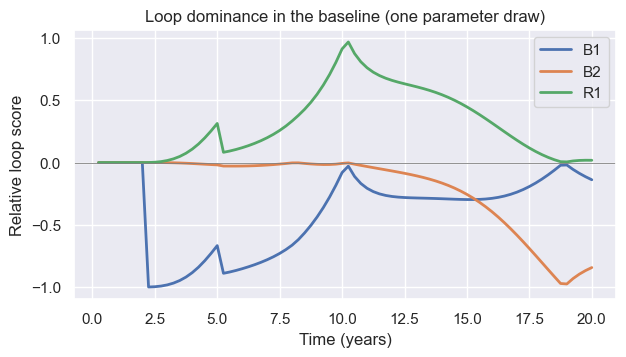

In [8]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 3.5))
for name in ltm.loop_names:
    ax.plot(loop_scores["time"], loop_scores[f"{name}_relative"], lw=2, label=name)
ax.axhline(0, color="grey", lw=0.6)
ax.set_xlabel("Time (years)")
ax.set_ylabel("Relative loop score")
ax.set_title("Loop dominance in the baseline (one parameter draw)")
ax.legend();

The loops take turns. Before `t = 2` nothing moves and every score is zero. The balancing
**attrition** loop B1 dominates while the first installers qualify; the reinforcing loop R1
(retrofits → awareness → enrolment → trainees → installers) takes over around year 10; and the
balancing **saturation** loop B2 (fewer homes are left to retrofit) dominates by year 20, as
growth slows: a reinforcing loop meeting a limit, the structure behind S-shaped growth (see
[reading trajectories](../docs/trajectories-and-archetypes.html)).

## Which uncertain parameters matter? (`run_GSA`, `sample_outcomes`)

Sensitivity analysis and the ensemble behind scenario discovery sample the same ranges as
`run_simulations`: the Parameters sheet for the named parameters, `[0, parameter_value_aux]`
for `#1`. Every link points into a variable with an equation, so no link coefficient is sampled:
the model has seven uncertain parameters. By default `run_GSA` analyses the outcome (the final
`Homes retrofitted`) with every lever at intensity 1; Borgonovo's δ (`method="delta"`)
measures how much each parameter shifts the whole distribution of that outcome.

,parameter,delta,delta_conf,S1,S1_conf
0,#productivity,0.312,0.027,0.575,0.050
1,#enrol_rate,0.235,0.029,0.279,0.064
2,#attrition_rate,0.104,0.020,0.019,0.021
3,#forgetting,0.096,0.022,0.016,0.019
4,#completion_rate,0.081,0.022,0.015,0.039
5,#word_of_mouth,0.074,0.021,0.011,0.018
6,Enrolment | #1,0.053,0.026,0.051,0.034


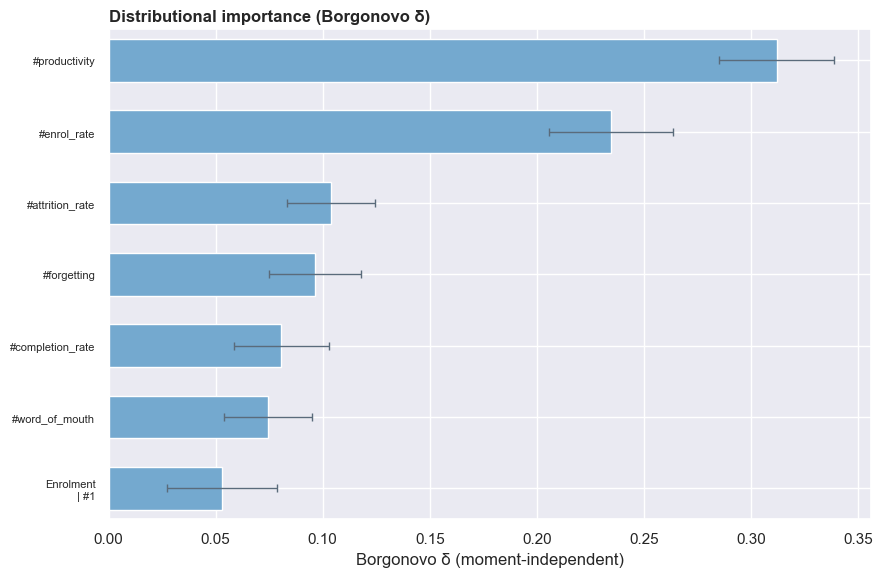

In [9]:
from sip_systemsinsightpipeline.plots import plot_moment_independent

delta = sdm.run_GSA(method="delta", n=500, seed=1, show_progress=False)
fig = plot_moment_independent(delta)
delta.round(3)

How fast installers retrofit (`#productivity`) and how many trainees the programme enrols
(`#enrol_rate`) drive the outcome; how long a course takes (`#completion_rate`) matters little
over 20 years.

The *effect* of the levers can depend on other parameters than the outcome does.
`relative_to="baseline"` analyses the effect instead, here with the ensemble `sample_outcomes`
draws (the input of `discover_scenarios`):

In [10]:
X, y = sdm.sample_outcomes(n=300, seed=2, relative_to="baseline", show_progress=False)
print(f"effect of all three levers: median {np.median(y):.3f}, range {y.min():.3f} to {y.max():.3f}")
X.corrwith(pd.Series(y), method="spearman").sort_values().round(2).to_frame("Spearman rho with the effect")

effect of all three levers: median 0.337, range 0.119 to 0.480


,Spearman rho with the effect
#enrol_rate,-0.50
#productivity,-0.29
#forgetting,-0.16
#word_of_mouth,-0.07
#completion_rate,0.02
#attrition_rate,0.31
Enrolment | #1,0.45


The levers add most when `#1` is large (the awareness campaign then reaches enrolment) or
attrition is high (the retention bonus then keeps more installers), and least when the baseline
is already strong: with a high `#enrol_rate` or `#productivity` many homes are retrofitted
without the levers, and fewer are left before the market saturates. The
[GSA and scenario discovery tutorial](GSA_and_Scenario_Discovery.ipynb) turns such an ensemble
into the conditions under which an outcome goes wrong.

## Solver settings

The phase-in has kinks at `t = 2` and `t = 5`, which the default adaptive solver (`LSODA`)
handles. System dynamics tools usually integrate with a fixed step; SIP's `RK4` gives the same
result. Equations that switch abruptly (e.g. `(S < 0.5)`) are where the fixed-step methods
matter: see *Integration settings* in the [README](../README.md).

In [11]:
full_package = np.ones(len(s.intervention_variables))
lsoda = sdm.run_SDM_with_intervention_intensities(full_package, params)
sdm.solver, sdm.solver_options["dt"] = "RK4", 0.01
rk4 = sdm.run_SDM_with_intervention_intensities(full_package, params)
sdm.solver = "LSODA"
print(f"largest difference in {voi}: {np.abs(rk4[voi] - lsoda[voi]).max():.1e}")

largest difference in Homes retrofitted: 3.4e-07


## Next steps

- Use [`StockFlow.xlsx`](StockFlow.xlsx) as a template for your own stock-and-flow model. The
  [README](../README.md) documents the equation syntax, named parameters, how effects are
  defined and the integration settings.
- [`Insulation.ipynb`](Insulation.ipynb) shows intervention ranking, budget optimisation and
  Loops That Matter on a 57-variable participatory model.
- [`GSA_and_Scenario_Discovery.ipynb`](GSA_and_Scenario_Discovery.ipynb) goes deeper into
  sensitivity analysis and scenario discovery.